
Stationary WindowSHAP: mean (SD) over the repetitions


source,pattern,key number,ground truth,true logit,GRU,TabPFN
0,W1,visit 10,0.3 (0.0),0.3 (0.0),0.22 (0.04),0.28 (0.04)
1,W1,visits 6-9,0.3 (0.0),0.3 (0.0),0.22 (0.04),0.28 (0.04)
2,W1,MAE truth != 0,-,0.0 (0.0),0.08 (0.04),0.04 (0.03)
3,W1,MAE truth = 0,-,0.0 (0.0),0.0 (0.0),0.01 (0.0)
4,W1,seconds per person,-,0.06 (0.0),0.04 (0.0),3.14 (0.01)
5,W2,visits 6-8,0.3 (0.0),0.3 (0.0),0.27 (0.0),0.27 (0.01)
6,W2,visits 9-10,0.3 (0.0),0.3 (0.0),0.27 (0.0),0.27 (0.01)
7,W2,MAE truth != 0,-,0.0 (0.0),0.04 (0.0),0.03 (0.01)
8,W2,MAE truth = 0,-,0.0 (0.0),0.0 (0.0),0.0 (0.0)
9,W2,seconds per person,-,0.03 (0.0),0.03 (0.0),3.14 (0.02)



Sliding WindowSHAP: mean (SD) over the repetitions


source,pattern,key number,ground truth,true logit,GRU,TabPFN
0,W1,visit 10,1.5 (0.0),1.5 (0.0),1.1 (0.19),1.38 (0.22)
1,W1,visits 6-9,0.48 (0.0),0.48 (0.0),0.36 (0.07),0.45 (0.07)
2,W1,MAE truth != 0,-,0.0 (0.0),0.19 (0.08),0.09 (0.07)
3,W1,MAE truth = 0,-,0.0 (0.0),0.01 (0.01),0.03 (0.01)
4,W1,seconds per person,-,0.09 (0.0),0.07 (0.0),17.14 (0.16)
5,W2,visits 6-8,1.34 (0.0),1.34 (0.0),1.19 (0.03),1.16 (0.07)
6,W2,visits 9-10,1.5 (0.0),1.5 (0.0),1.33 (0.03),1.35 (0.04)
7,W2,MAE truth != 0,-,0.0 (0.0),0.16 (0.01),0.2 (0.06)
8,W2,MAE truth = 0,-,0.0 (0.0),0.02 (0.0),0.02 (0.0)
9,W2,seconds per person,-,0.09 (0.0),0.06 (0.0),17.08 (0.0)



Dynamic WindowSHAP: mean (SD) over the repetitions


source,pattern,key number,ground truth,true logit,GRU,TabPFN
0,W1,visit 10,0.75 (0.0),0.75 (0.0),0.55 (0.09),0.65 (0.13)
1,W1,visits 6-9,0.19 (0.0),0.19 (0.0),0.14 (0.02),0.18 (0.04)
2,W1,MAE truth != 0,-,0.0 (0.0),0.2 (0.09),0.13 (0.1)
3,W1,MAE truth = 0,-,0.0 (0.0),0.0 (0.0),0.01 (0.0)
4,W1,seconds per person,-,0.17 (0.01),0.17 (0.02),11.16 (0.27)
5,W2,visits 6-8,0.5 (0.0),0.5 (0.0),0.43 (0.02),0.42 (0.05)
6,W2,visits 9-10,-0.0 (0.0),0.0 (0.0),0.01 (0.02),0.03 (0.05)
7,W2,MAE truth != 0,-,0.0 (0.0),0.08 (0.0),0.25 (0.08)
8,W2,MAE truth = 0,-,0.0 (0.0),0.0 (0.0),0.0 (0.0)
9,W2,seconds per person,-,0.19 (0.0),0.18 (0.0),8.04 (0.43)


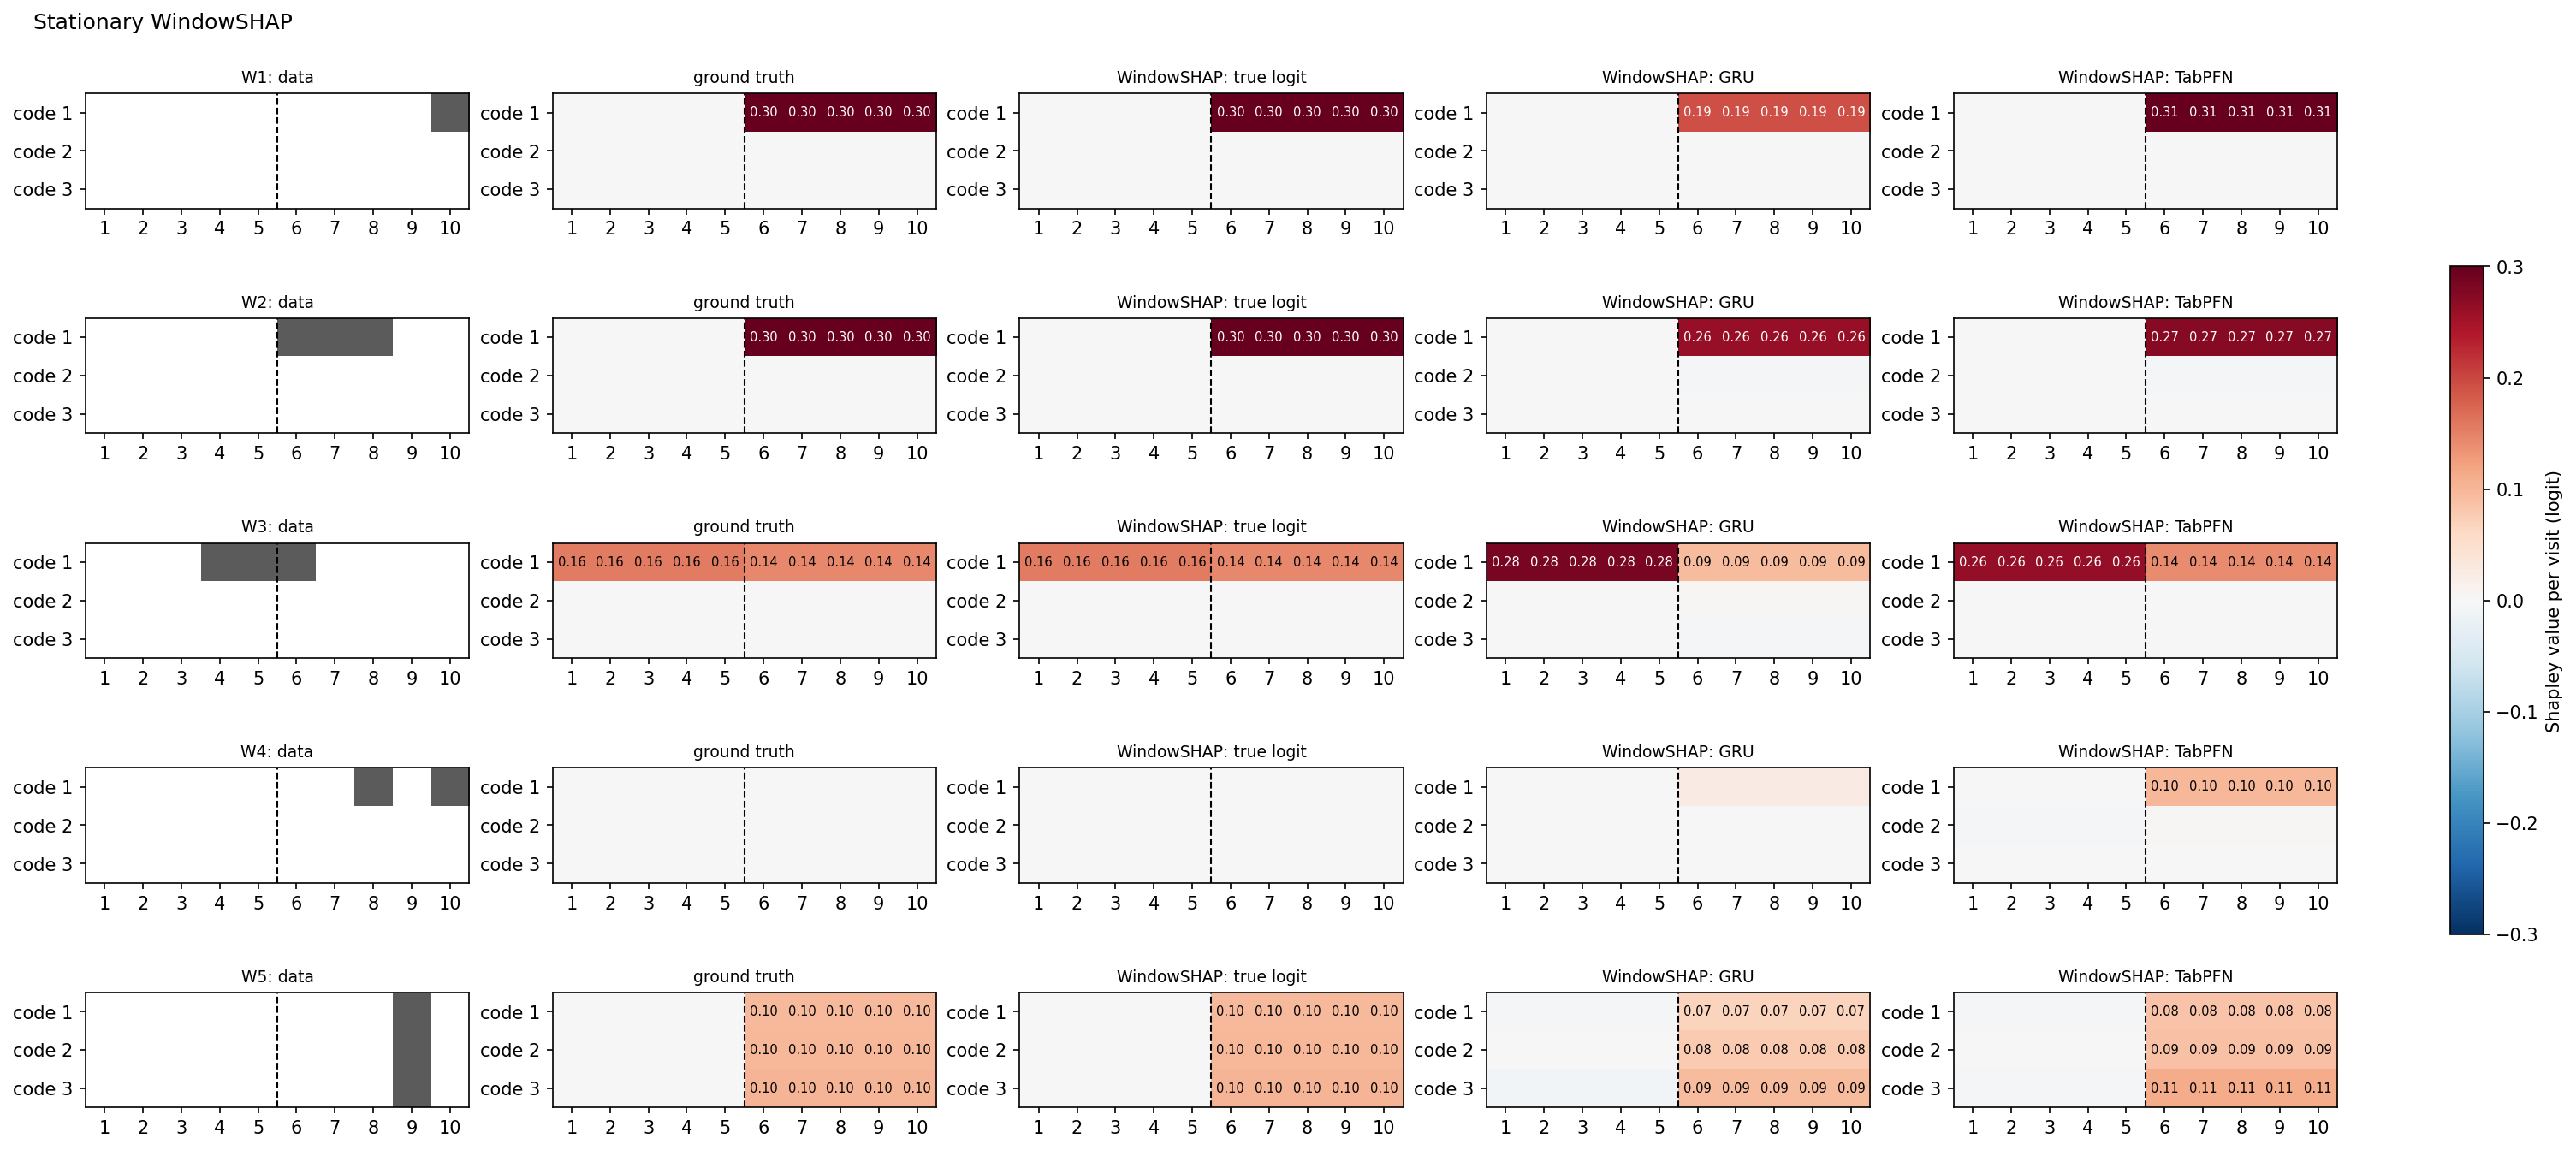

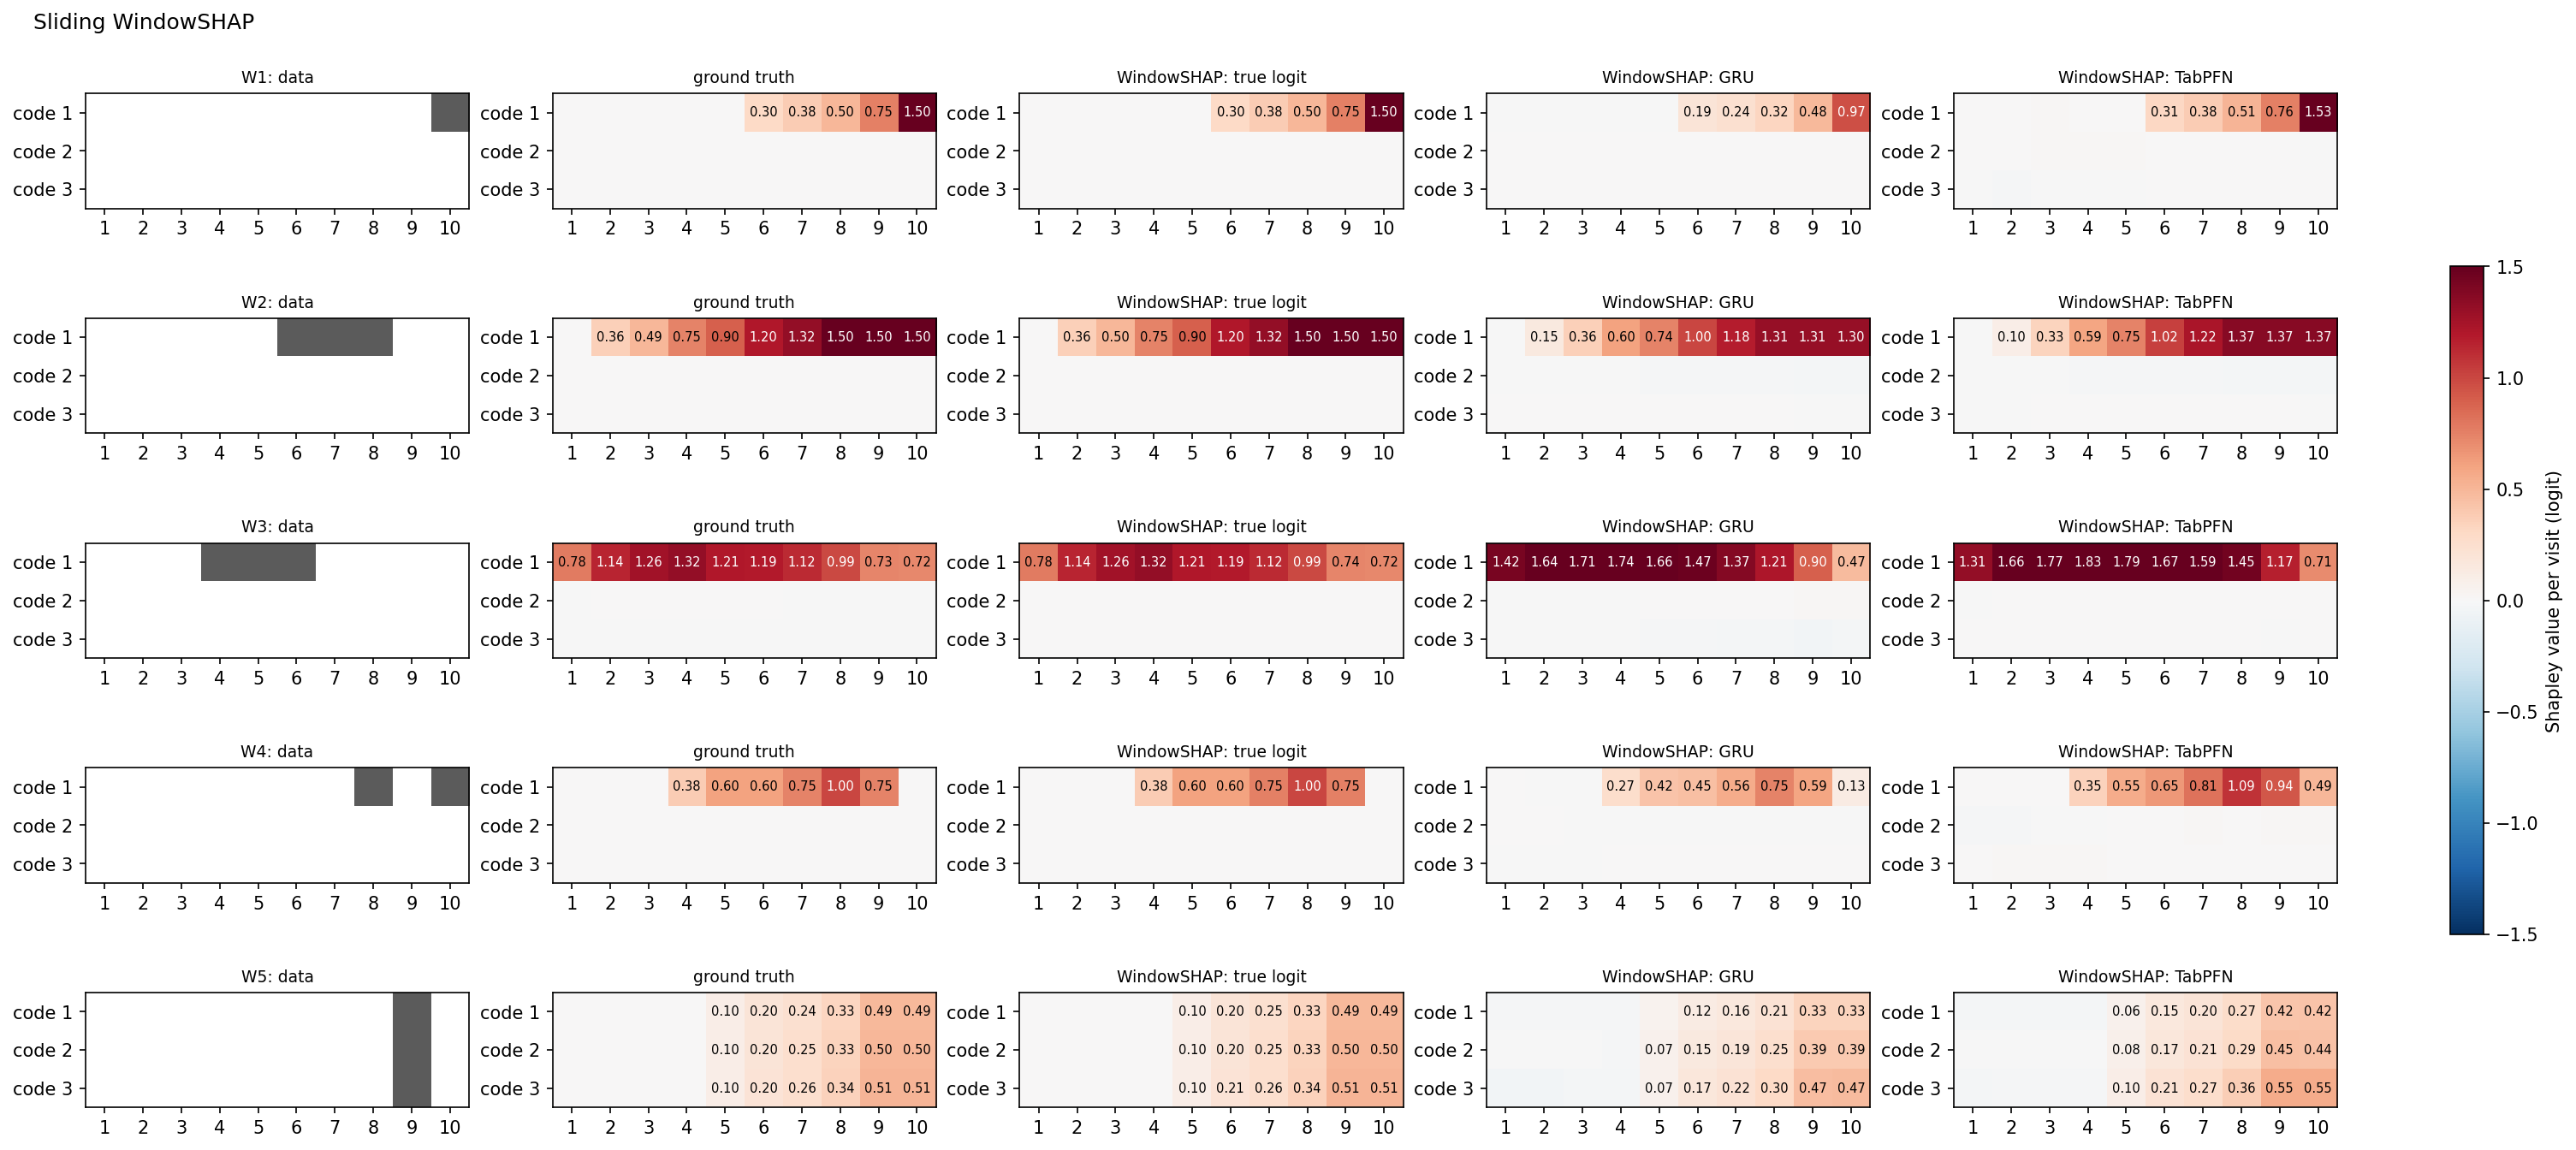

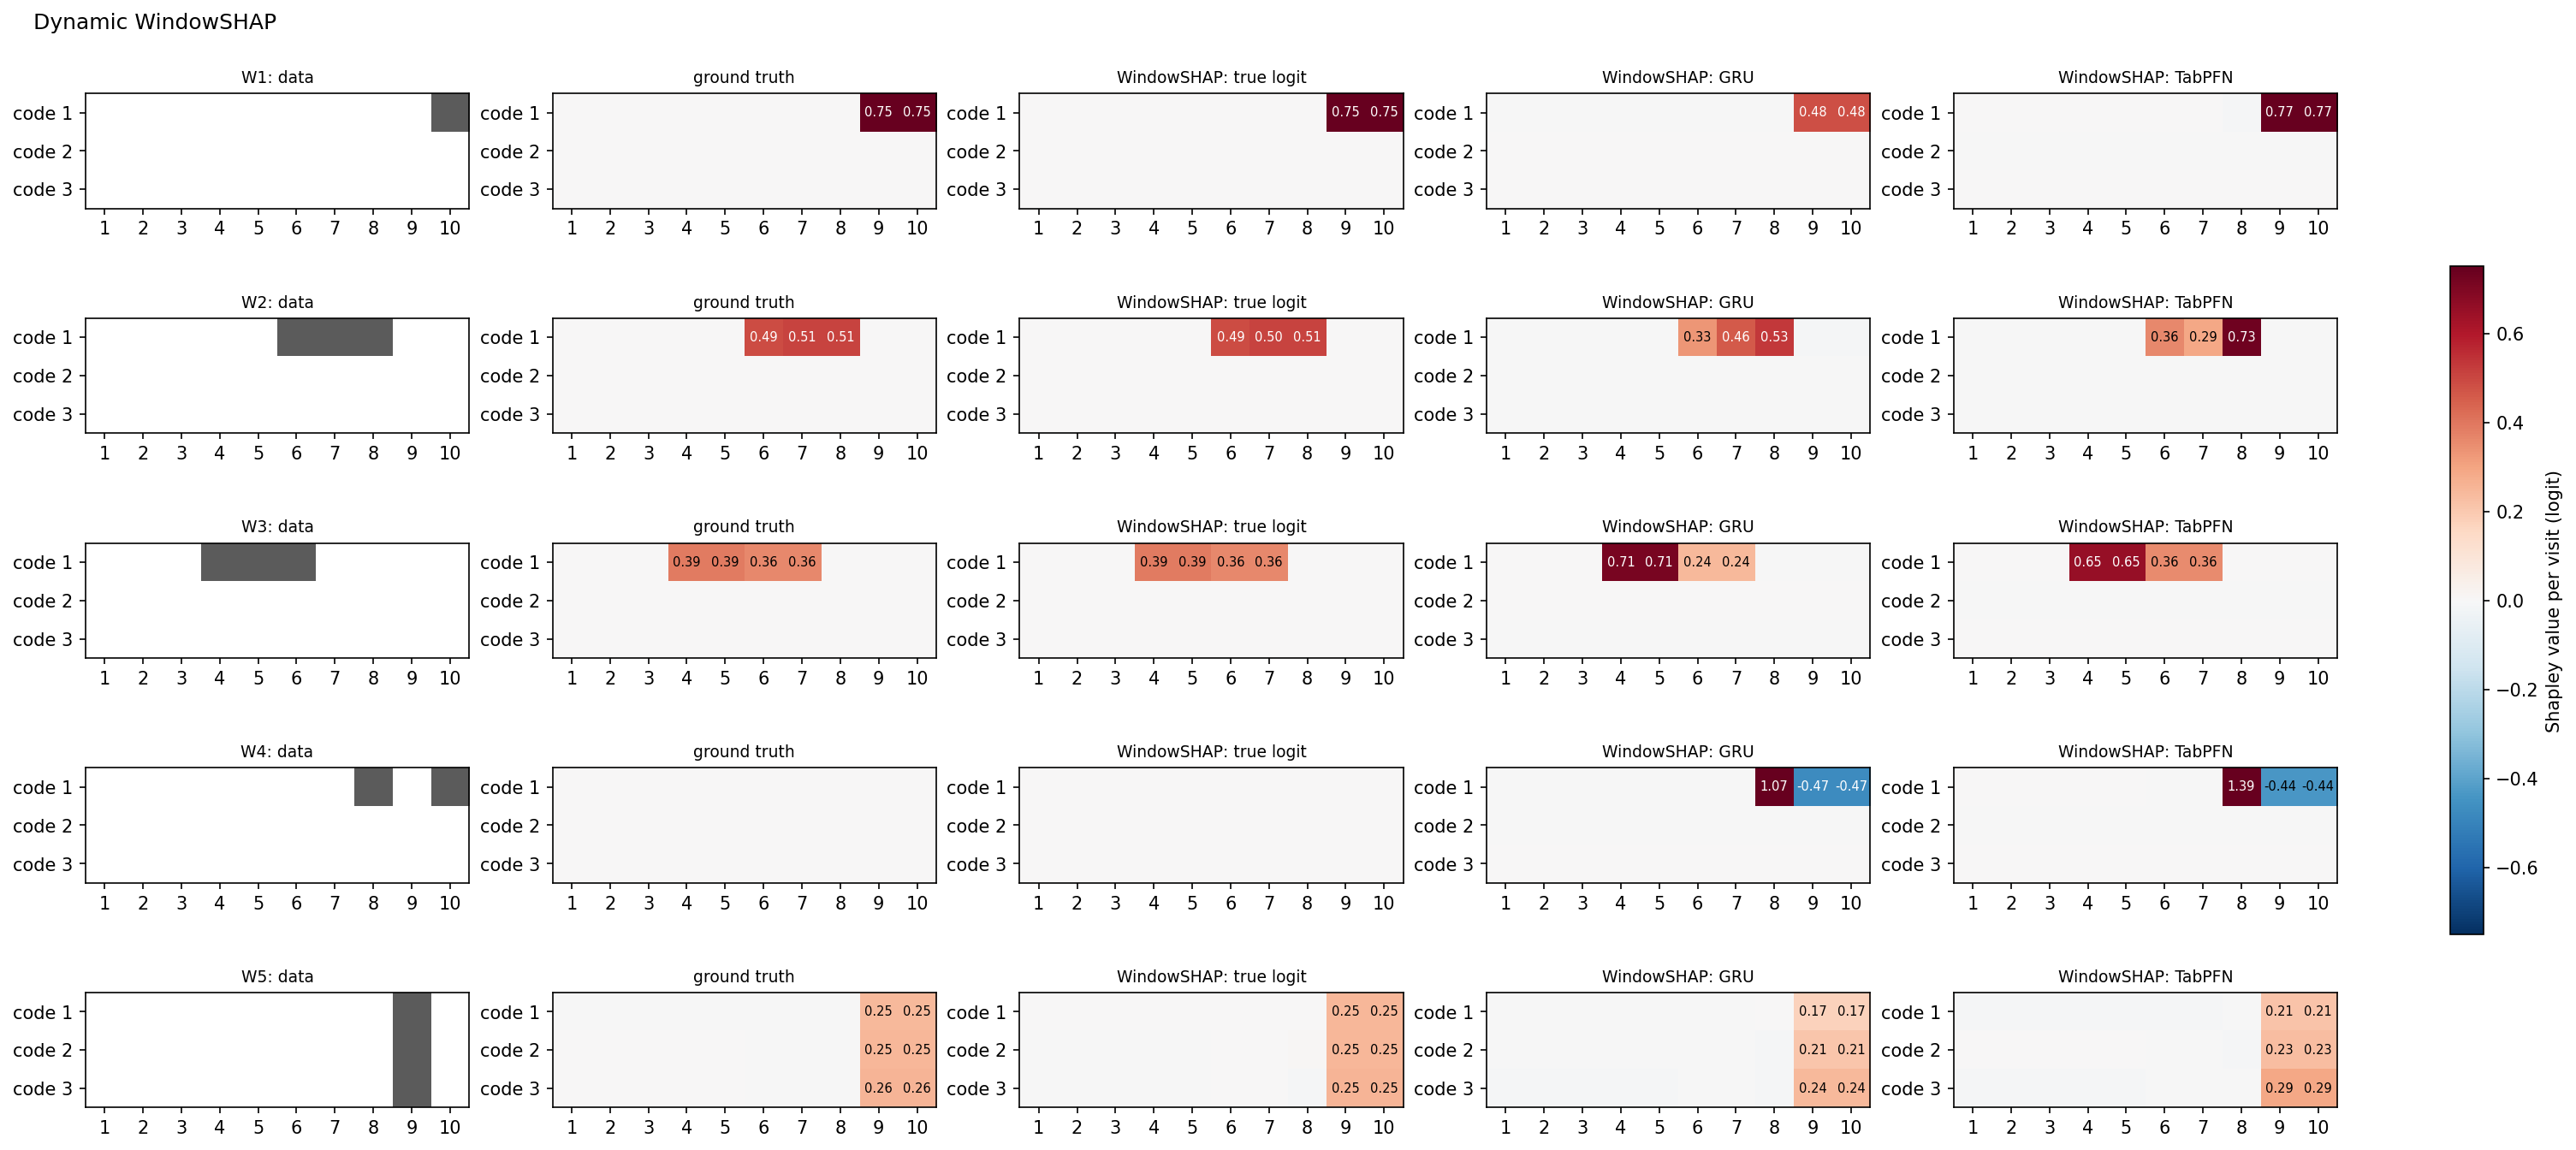

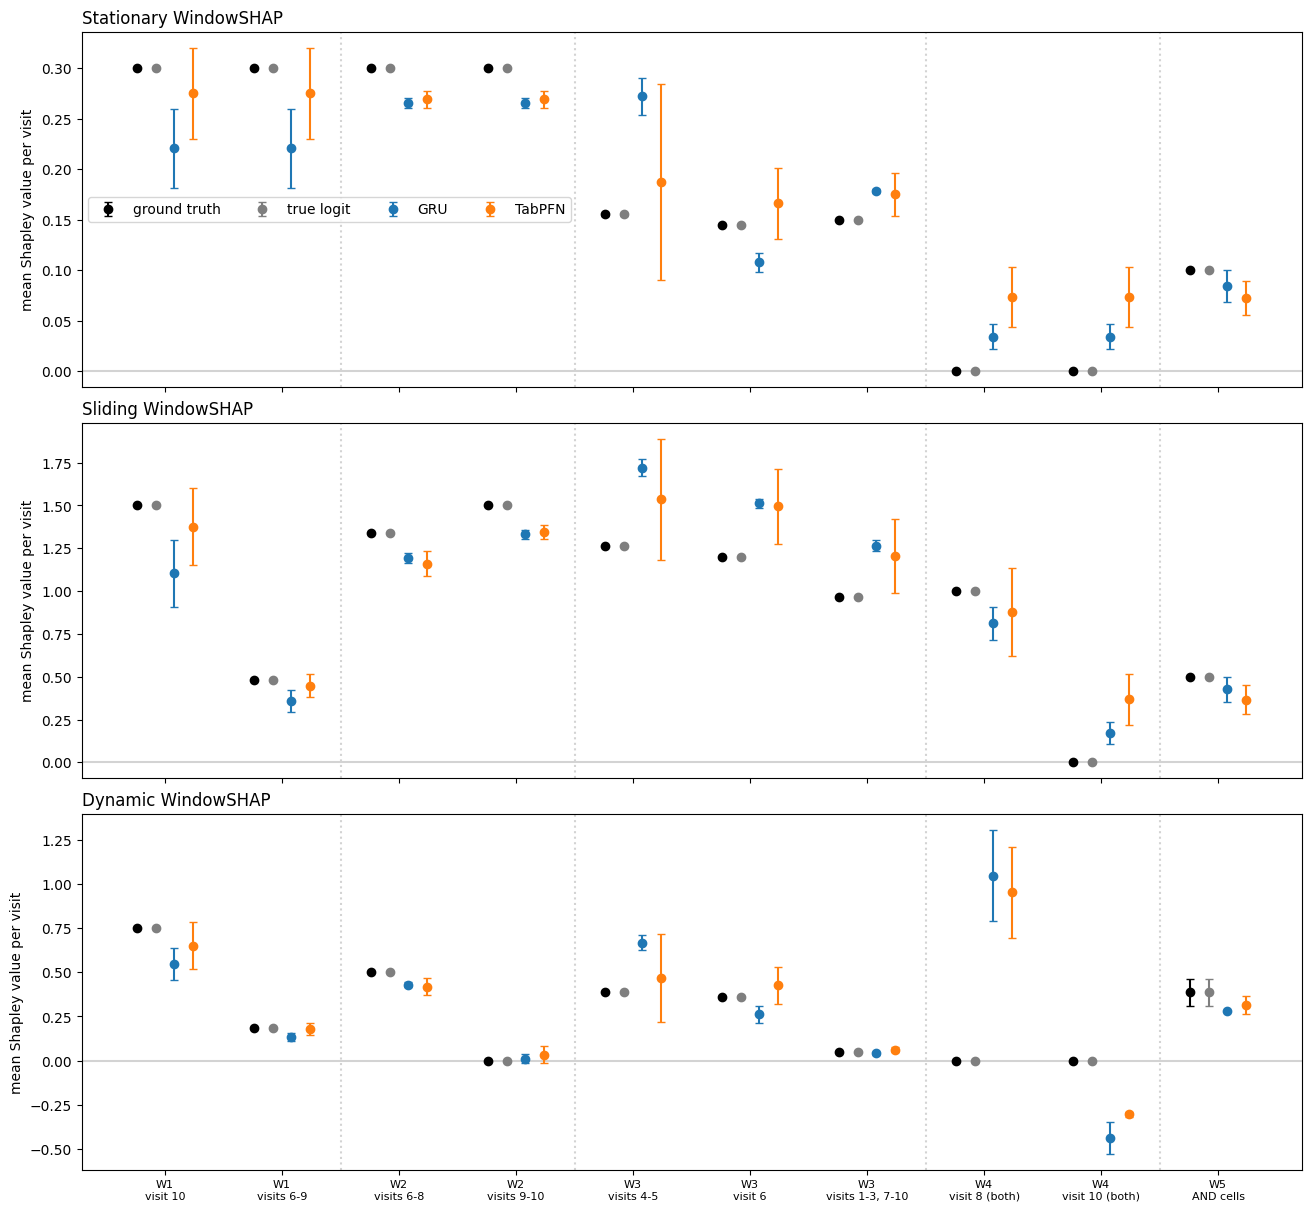

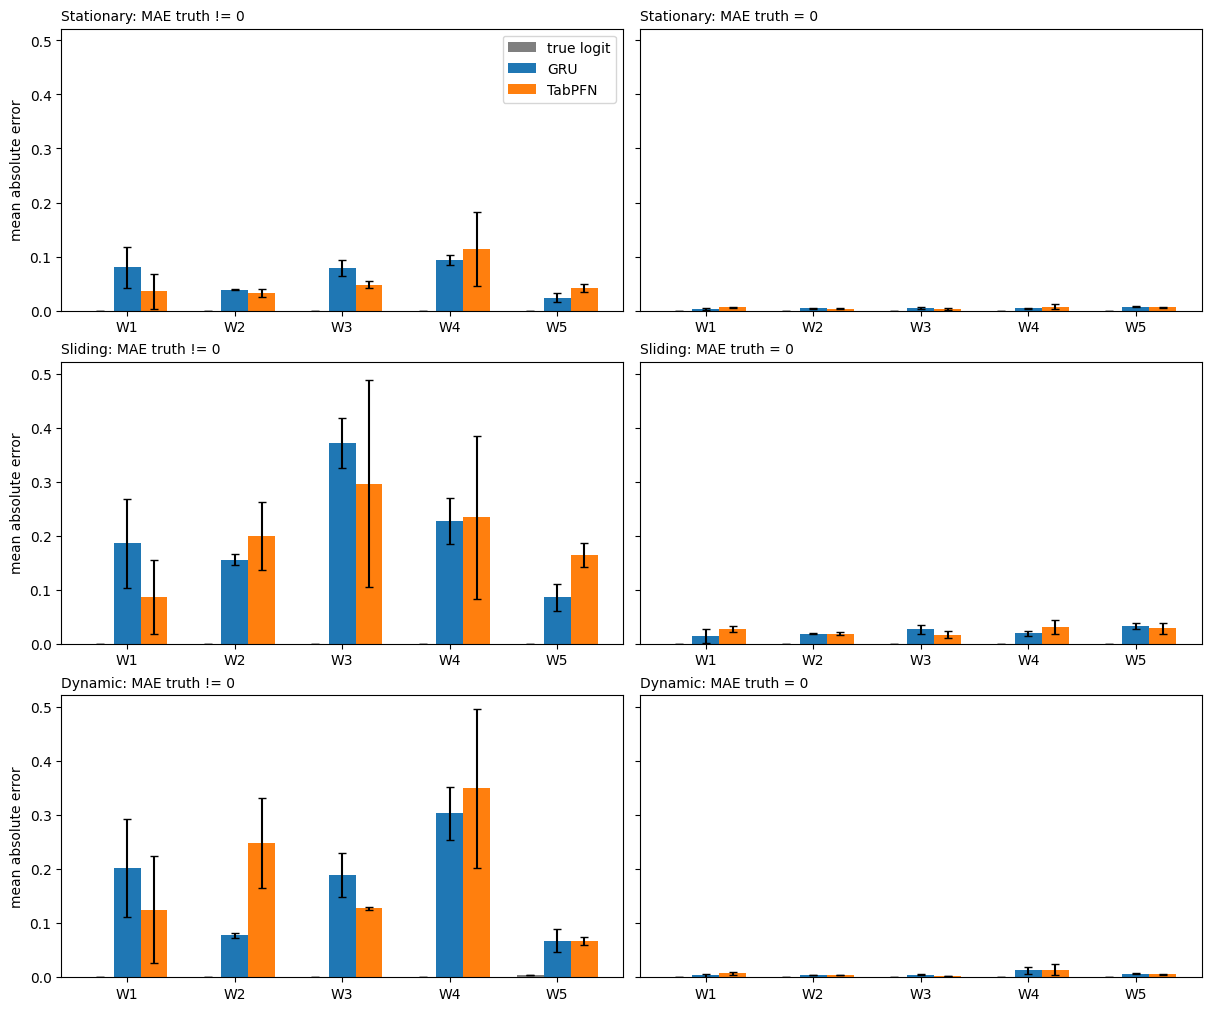

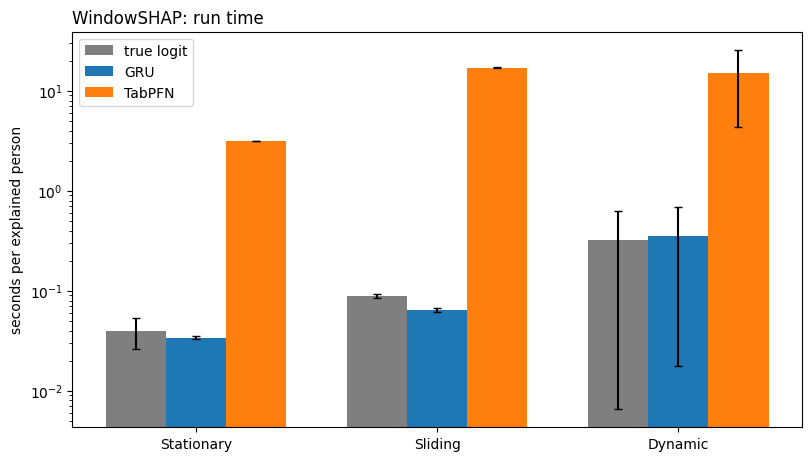

source,ground truth,true logit,GRU,TabPFN
rep,,,,
0,0.0,0.0,1.23,0.77
1,0.0,0.0,0.86,1.13


In [1]:
#.......................................................................................
# Plot the results of the WindowSHAP simulation (analogous to the KernelSHAP plots)
# Reads results_windowshap.csv and heatmaps_windowshap_<version>.png
# (written by simulation_WindowSHAP.py). Run it in Positron/Jupyter in the same folder.
#.......................................................................................

#.......................................................................................
# Load the results
#.......................................................................................

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

results = pd.read_csv("results_windowshap.csv")

versions = ["stationary", "sliding", "dynamic"]
sources = ["ground truth", "true logit", "GRU", "TabPFN"]
models = ["true logit", "GRU", "TabPFN"]
patterns = ["W1", "W2", "W3", "W4", "W5"]

#.......................................................................................
# 1. Tables: mean (SD) over the repetitions, one table per version
#.......................................................................................

for version in versions:
    r = results[results["version"] == version]
    means = r.groupby(["pattern", "key number", "source"], sort=False)["value"].mean().unstack()
    sds = r.groupby(["pattern", "key number", "source"], sort=False)["value"].std().unstack()

    table = means.round(2).astype(str) + " (" + sds.fillna(0).round(2).astype(str) + ")"
    table = table.where(means.notna(), "-")[sources]

    # rows in the order in which they were computed
    order = list(r[["pattern", "key number"]].drop_duplicates().itertuples(index=False, name=None))
    print(f"\n{version.capitalize()} WindowSHAP: mean (SD) over the repetitions")
    display(table.loc[order].reset_index())

#.......................................................................................
# 2. Heatmaps of the example persons (last repetition), one figure per version
#.......................................................................................

for version in versions:
    display(Image(f"heatmaps_windowshap_{version}.png"))

#.......................................................................................
# 3. Plot: key numbers per pattern, one panel per version
# One point per source (mean over the repetitions), bars = SD.
# The ground truth (black) is the reference: values per visit.
#.......................................................................................

key_numbers = [("W1", "visit 10"), ("W1", "visits 6-9"),
               ("W2", "visits 6-8"), ("W2", "visits 9-10"),
               ("W3", "visits 4-5"), ("W3", "visit 6"), ("W3", "visits 1-3, 7-10"),
               ("W4", "visit 8 (both)"), ("W4", "visit 10 (both)"),
               ("W5", "AND cells")]
labels = [f"{p}\n{k}" for p, k in key_numbers]
x = np.arange(len(key_numbers))
colors = {"ground truth": "black", "true logit": "tab:grey", "GRU": "tab:blue", "TabPFN": "tab:orange"}

fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True, layout="constrained")

for ax, version in zip(axes, versions):
    r = results[results["version"] == version]
    means = r.groupby(["pattern", "key number", "source"])["value"].mean()
    sds = r.groupby(["pattern", "key number", "source"])["value"].std().fillna(0)

    ax.axhline(0, color="lightgrey")
    for i, source in enumerate(sources):
        m = [means.get((p, k, source), np.nan) for p, k in key_numbers]
        s = [sds.get((p, k, source), np.nan) for p, k in key_numbers]
        ax.errorbar(x - 0.24 + 0.16 * i, m, yerr=s, fmt="o", capsize=3,
                    color=colors[source], label=source)

    # light grey lines between the patterns
    for b in [1.5, 3.5, 6.5, 8.5]:
        ax.axvline(b, color="lightgrey", linestyle=":")
    ax.set_ylabel("mean Shapley value per visit")
    ax.set_title(f"{version.capitalize()} WindowSHAP", loc="left")

axes[0].legend(ncol=4)
axes[-1].set_xticks(x, labels, fontsize=8)
plt.savefig("key_numbers_windowshap.png", dpi=150, bbox_inches="tight")
plt.show()

#.......................................................................................
# 4. Plot: errors against the ground truth (WindowSHAP only), one row per version
# Left: on the cells where the ground truth gives credit (truth != 0);
# right: spurious credit on the cells where the ground truth is 0 (truth = 0)
#.......................................................................................

fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharey=True, layout="constrained")
x = np.arange(len(patterns))

for row, version in enumerate(versions):
    r = results[results["version"] == version]
    means = r.groupby(["pattern", "key number", "source"])["value"].mean()
    sds = r.groupby(["pattern", "key number", "source"])["value"].std().fillna(0)

    for col, key in enumerate(["MAE truth != 0", "MAE truth = 0"]):
        ax = axes[row, col]
        for i, model in enumerate(models):
            m = [means.get((p, key, model), np.nan) for p in patterns]
            s = [sds.get((p, key, model), np.nan) for p in patterns]
            ax.bar(x - 0.25 + 0.25 * i, m, width=0.25, yerr=s, capsize=3,
                   color=colors[model], label=model)
        ax.set_xticks(x, patterns)
        ax.set_title(f"{version.capitalize()}: {key}", loc="left", fontsize=10)
    axes[row, 0].set_ylabel("mean absolute error")

axes[0, 0].legend()
plt.savefig("errors_windowshap.png", dpi=150, bbox_inches="tight")
plt.show()

#.......................................................................................
# 5. Plot: run time per explained person, per version and model
# Mean over all patterns and repetitions; bars = SD. Log scale, because the versions
# differ by orders of magnitude.
# Note: true logit and GRU run on n_jobs CPU cores, TabPFN on one GPU.
#.......................................................................................

r = results[results["key number"] == "seconds per person"]
means = r.groupby(["version", "source"])["value"].mean()
sds = r.groupby(["version", "source"])["value"].std().fillna(0)

fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
x = np.arange(len(versions))
for i, model in enumerate(models):
    m = [means.get((v, model), np.nan) for v in versions]
    s = [sds.get((v, model), np.nan) for v in versions]
    ax.bar(x - 0.25 + 0.25 * i, m, width=0.25, yerr=s, capsize=3, color=colors[model], label=model)
ax.set_xticks(x, [v.capitalize() for v in versions])
ax.set_yscale("log")
ax.set_ylabel("seconds per explained person")
ax.set_title("WindowSHAP: run time", loc="left")
ax.legend()
plt.savefig("runtime_windowshap.png", dpi=150, bbox_inches="tight")
plt.show()

#.......................................................................................
# 6. Optional: every repetition separately, e.g. how stable W4 is with dynamic WindowSHAP
#.......................................................................................

w4 = results[(results["version"] == "dynamic") & (results["pattern"] == "W4") &
             (results["key number"] == "visit 8 (both)")]
display(w4.pivot(index="rep", columns="source", values="value")[sources].round(2))

In [2]:
# In Terminal:
# diff -u windowshap_unpatched/windowshap_original.py $F > windowshap_unpatched/windowshap_fix.patch
# cat windowshap_unpatched/windowshap_fix.patch